# 01_setup_eda.ipynb
Quick exploratory analysis for retail transactions.

## 1) Imports

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## 2) Load CSV

In [3]:
csv_path = "../data/raw/transactions_sample.csv"
df = pd.read_csv(csv_path)
df.head()

,order_id,date,category,product,quantity,price,sales
0,200001,2024-11-27,Groceries,Bread,1,528.53,528.53
1,200002,2024-09-03,Electronics,Charger,1,17321.75,17321.75
2,200003,2024-05-16,Clothing,Shoes,2,2323.86,4647.72
3,200004,2024-04-09,Beauty,Shampoo,5,1831.90,9159.50
4,200005,2024-09-11,Books,Textbook,2,954.17,1908.34


## 3) Quick Look

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  600 non-null    int64  
 1   date      600 non-null    object 
 2   category  592 non-null    object 
 3   product   584 non-null    object 
 4   quantity  600 non-null    int64  
 5   price     600 non-null    float64
 6   sales     600 non-null    float64
dtypes: float64(2), int64(2), object(3)
memory usage: 32.9+ KB


In [5]:
df.describe(include='all')

,order_id,date,category,product,quantity,price,sales
count,600.000000,600,592,584,600.000000,600.000000,600.000000
unique,NaN,378,7,28,NaN,NaN,NaN
top,NaN,2024-06-17,Beauty,Shoes,NaN,NaN,NaN
freq,NaN,6,89,27,NaN,NaN,NaN
mean,200300.500000,NaN,NaN,NaN,2.926667,3067.728517,9342.996933
std,173.349358,NaN,NaN,NaN,1.417028,4747.803344,17406.771163
min,200001.000000,NaN,NaN,NaN,1.000000,37.930000,48.280000
25%,200150.750000,NaN,NaN,NaN,2.000000,533.727500,1337.662500
50%,200300.500000,NaN,NaN,NaN,3.000000,1397.960000,3454.140000
75%,200450.250000,NaN,NaN,NaN,4.000000,3132.662500,8456.205000


In [6]:
df.isna().sum()

order_id     0
date         0
category     8
product     16
quantity     0
price        0
sales        0
dtype: int64

## 4) Cleaning

In [7]:
df = df.dropna(subset=["sales", "quantity", "price"])
df["category"] = df["category"].replace("", pd.NA).fillna("Unknown")
df["product"] = df["product"].replace("", pd.NA).fillna("Unknown")
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date"])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   order_id  600 non-null    int64         
 1   date      600 non-null    datetime64[ns]
 2   category  600 non-null    object        
 3   product   600 non-null    object        
 4   quantity  600 non-null    int64         
 5   price     600 non-null    float64       
 6   sales     600 non-null    float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(2)
memory usage: 32.9+ KB


## 5) Quick Insights

In [8]:
top_cats = df.groupby("category")["sales"].sum().nlargest(5)
print("Top 5 categories by sales:")
print(top_cats)

Top 5 categories by sales:
category
Electronics    3470641.13
Home            560842.75
Clothing        473468.15
Beauty          429918.22
Toys            375226.88
Name: sales, dtype: float64


In [9]:
monthly_sales = df.groupby(df["date"].dt.to_period("M"))["sales"].sum().sort_index()
monthly_sales.head()

date
2024-01    388894.39
2024-02    192069.45
2024-03    234640.37
2024-04    243171.67
2024-05    252036.59
Freq: M, Name: sales, dtype: float64

## 6) Visualizations

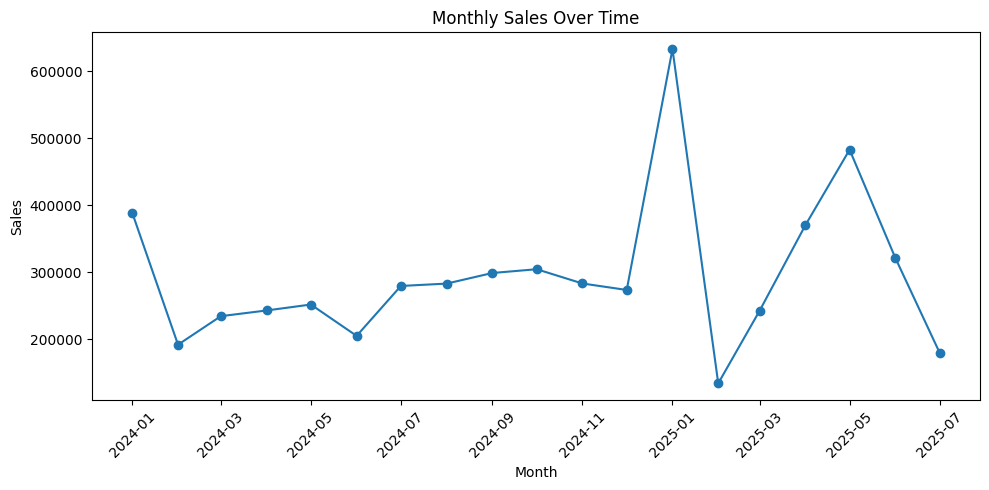

In [10]:
# Line chart — monthly sales over time
plt.figure(figsize=(10, 5))
monthly_sales.index = monthly_sales.index.to_timestamp()
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Sales Over Time")
plt.ylabel("Sales")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

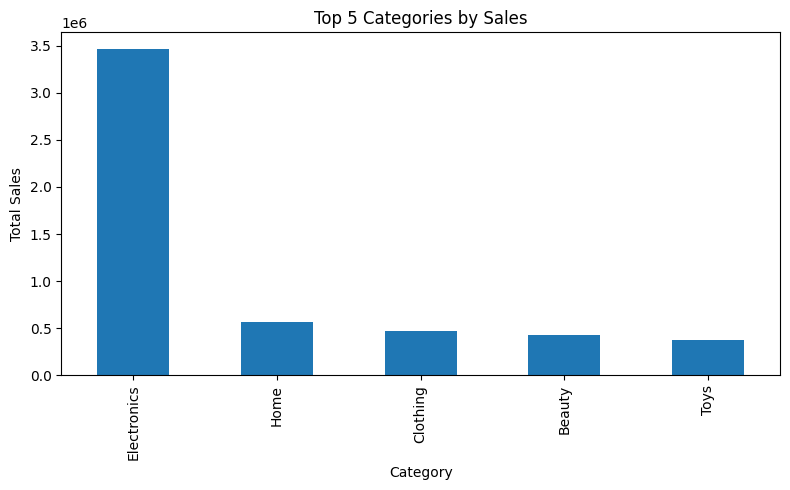

In [11]:
# Bar chart — Top 5 categories
plt.figure(figsize=(8, 5))
top_cats.plot(kind="bar")
plt.title("Top 5 Categories by Sales")
plt.ylabel("Total Sales")
plt.xlabel("Category")
plt.tight_layout()
plt.show()